<a href="https://colab.research.google.com/github/Nasim-Amani/ramp-aware-solar/blob/main/E3_Ramp_Risk_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ramp-risk test: can the LSTM forecast the chance of a ramp in the next minute?

## Why this test
E1 and E2 showed that, with past irradiance as the only input, the LSTM can hardly forecast **when** a cloud arrives: drops were caught at most about 10 % of the time, and the ramp-aware loss mainly increased recall through oscillating forecasts. The data exploration, however, showed that the **chance** of a ramp is predictable: a ramp in the next 60 s followed in 3 % of the cases after a calm period, but in 55 % after many recent ramps.

**Question:** can an LSTM forecast the probability of a ramp in the next 60 s, and is it better than simple rules based on recent ramps?

## What changes compared with E1/E2
| | E1/E2 | This test |
|---|---|---|
| Output | 6 values: irradiance at +10, …, +60 s | **1 value between 0 and 1**: the chance of a ramp in the next 60 s |
| Label | the measured irradiance | **1** if the measured path (now → +60 s) contains a 10-s change > 80 W/m², else **0** |
| Loss | MSE (+ ramp term) | **binary cross-entropy**, the standard loss for yes/no forecasts |

Input, split, threshold and windows are the same as in E1 (last 10 min of 10-s irradiance; train 16–23 Feb, validation 24 Feb, test 25–26 Feb). This is a quick test with one seed.

## Methods compared
1. **Constant:** always the share of ramp minutes in the training data (no skill; reference).
2. **Recent-ramps rule:** the chance of a ramp observed in the training data for the same number of ramps in the last 5 minutes (0, 1, 2, …). This uses the main finding of the data exploration.
3. **Logistic regression** on three simple features of the last minutes: the number of ramps in the last 5 min and the standard deviation of the 10-s changes in the last 1 and 5 min.
4. **LSTM** on the full last 10 minutes.

## Evaluation (test days)
- **ROC-AUC:** how well a method separates minutes with and without a coming ramp (0.5 = no skill, 1 = perfect).
- **PR-AUC (average precision):** the same idea, focused on the rare ramp minutes; its no-skill value is the share of ramp minutes.
- **Brier score:** the mean squared error of the probabilities (lower is better), and the **Brier skill score** against the constant method (above 0 = better than the constant).
- **Reliability plot:** when a method says 40 %, does a ramp follow about 40 % of the time?

**Decision rule:** if the LSTM is clearly better than the recent-ramps rule and the logistic regression (e.g. ROC-AUC higher by a few hundredths on the broken-cloud day), forecasting ramp risk with the LSTM becomes the main direction; if not, the simple rules already capture the signal.

## 1. Settings

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

STEP_S   = 10                          # resolution: 10-s averages
LOOKBACK = 60                          # input:  the last 60 steps (10 min)
HORIZON  = 6                           # the label looks at the next 6 steps (60 s)
SEED     = 0                           # quick test: one seed

HP = {"units": 64, "learning_rate": 1e-3, "batch_size": 128,
      "max_epochs": 100, "patience": 10}   # same as E1

## 2. Data
1-s irradiance (`Solar_Rad_clean`), daylight records of the 11 complete days, averaged to 10 s (the model resolution chosen in the data exploration). Only irradiance is used as input in E1.

In [ ]:
df = pd.read_csv("solar_data_final_columns.csv", index_col="DateTime", parse_dates=["DateTime"])

data = (df.loc[df["full_day"] & df["daylight"], ["Solar_Rad_clean"]]
          .rename(columns={"Solar_Rad_clean": "G"})        # G = irradiance (W/m²)
          .resample(f"{STEP_S}s").mean()
          .dropna())     # removes only the night steps (checked: no NaN and no gaps inside daylight)

print(f"10-s daylight steps: {len(data):,}")

10-s daylight steps: 46,794


## 3. Split and day types
- **Split by whole days, in time order:** train 16–23 Feb, validation 24 Feb, test 25 Feb (broken clouds) and 26 Feb (clear).
- **Day types** come from the Variability Index in the data exploration notebook.

In [ ]:
days = sorted(set(data.index.date))
TRAIN_DAYS, VAL_DAYS, TEST_DAYS = days[:8], days[8:9], days[9:]

# Day types from the Variability Index (data exploration notebook)
DAY_TYPE = {pd.Timestamp(d).date(): typ for d, typ in {
    "2013-02-16": "clear",         "2013-02-17": "few clouds",    "2013-02-18": "broken clouds",
    "2013-02-19": "clear",         "2013-02-20": "broken clouds", "2013-02-21": "clear",
    "2013-02-22": "clear",         "2013-02-23": "few clouds",    "2013-02-24": "broken clouds",
    "2013-02-25": "broken clouds", "2013-02-26": "clear"}.items()}

for name, dl in [("train", TRAIN_DAYS), ("validation", VAL_DAYS), ("test", TEST_DAYS)]:
    print(f"{name:11s}", ", ".join(f"{d:%d %b} ({DAY_TYPE[d]})" for d in dl))

train       16 Feb (clear), 17 Feb (few clouds), 18 Feb (broken clouds), 19 Feb (clear), 20 Feb (broken clouds), 21 Feb (clear), 22 Feb (clear), 23 Feb (few clouds)
validation  24 Feb (broken clouds)
test        25 Feb (broken clouds), 26 Feb (clear)


## 4. Ramp threshold

**Goal:** decide how large a 10-s change must be to count as a ramp, based on the data.

1. **10-s changes.** For each day, we subtract each 10-s value from the next one, e.g. 790 → 650 W/m² gives a change of −140 W/m². Changes are only computed between values that are exactly 10 s apart.
2. **Which days.** We use only the broken-cloud **training** days (18 and 20 Feb): clear days have almost only tiny changes, and the test days must not influence a threshold that is later used to score the models. Drops and rises are treated the same, so we use the size of each change (−140 and +140 both count as 140).
3. **Threshold.** A ramp is a change among the largest 5 % of these changes, i.e. larger than their 95th percentile. Rounded to 10 W/m², this gives **80 W/m² per 10 s**.

All ramp results use this threshold. As a sensitivity check, we also report results at 60 W/m².

In [ ]:
def changes_of_day(day):
    # 10-s changes of irradiance within one day, only between real neighbouring steps
    g = data.loc[data.index.date == day, "G"]
    ok = g.index.to_series().diff() == pd.Timedelta(seconds=STEP_S)
    return g.diff()[ok]

broken_train = [d for d in TRAIN_DAYS if DAY_TYPE[d] == "broken clouds"]
train_changes = pd.concat([changes_of_day(d) for d in broken_train]).abs()

THRESHOLD       = int(round(np.percentile(train_changes, 95), -1))   # main threshold (W/m² per 10 s)
THRESHOLD_CHECK = 60                                                  # sensitivity check
print(f"Ramp threshold: {THRESHOLD} W/m² per 10 s   (check: {THRESHOLD_CHECK})")

Ramp threshold: 80 W/m² per 10 s   (check: 60)


## 5. Training examples (windows)

Each training example is a **window** of 66 consecutive 10-s values: the first 60 (10 min) are the input, and the next 6 (10, 20, …, 60 s) are the targets. We slide this window forward one step at a time to create many examples.

- **One day per window.** Because the nights were removed, the last value of one day is directly followed by the first value of the next morning in the data, although 12 hours lie between them. We therefore cut windows inside each day separately, so no example mixes the evening of one day with the morning of the next.
- **No gaps.** A window is used only if its 66 values are exactly 10 s apart; windows with a missing step are skipped.
- **Current value.** For each example we also keep the current irradiance ("now", the last input value), which is needed for persistence and for the change target.

In [ ]:
def make_windows(days_list, inputs):
    # Returns X (examples, LOOKBACK, features), Y (examples, HORIZON) in W/m²,
    # now (examples, 1) = irradiance at the forecast time, and the forecast times
    X, Y, now, t = [], [], [], []
    span = pd.Timedelta(seconds=STEP_S * (LOOKBACK + HORIZON - 1))
    for day in days_list:
        d = data[data.index.date == day]
        n = len(d) - LOOKBACK - HORIZON + 1
        if n <= 0:
            continue
        start = np.arange(n)
        ok = (d.index[start + LOOKBACK + HORIZON - 1] - d.index[start]) == span   # no missing step inside
        x = np.lib.stride_tricks.sliding_window_view(d[inputs].to_numpy(), LOOKBACK, axis=0)[:n]
        y = np.lib.stride_tricks.sliding_window_view(d["G"].to_numpy(), HORIZON)[LOOKBACK:LOOKBACK + n]
        X.append(x.transpose(0, 2, 1)[ok])
        Y.append(y[ok])
        now.append(d["G"].to_numpy()[start + LOOKBACK - 1][ok])
        t.append(d.index[start + LOOKBACK - 1][ok])
    return (np.concatenate(X), np.concatenate(Y),
            np.concatenate(now)[:, None], pd.DatetimeIndex(np.concatenate(t)))


_windows = {}                          # windows are built once per input set and reused
def get_windows(inputs):
    key = tuple(inputs)
    if key not in _windows:
        _windows[key] = {name: make_windows(dl, inputs)
                         for name, dl in [("train", TRAIN_DAYS), ("val", VAL_DAYS), ("test", TEST_DAYS)]}
    return _windows[key]

w = get_windows(["G"])
print({name: len(v[0]) for name, v in w.items()}, " input shape:", w["train"][0].shape)

{'train': 33410, 'val': 4213, 'test': 8456}  input shape: (33410, 60, 1)


## 6. Labels and simple features
- **Label:** 1 if the measured path from now to +60 s contains at least one 10-s change larger than the threshold (up or down), else 0.
- **Simple features** (only from the input window, i.e. the past): number of ramps in the last 5 min, and the standard deviation of the 10-s changes in the last 1 min and the last 5 min.

In [ ]:
W = get_windows(["G"])                     # windows from section 5: (X, Y, now, t) for train / val / test

def labels_and_features(split):
    X, Y, now, t = W[split]
    future = np.abs(np.diff(np.hstack([now, Y]), axis=1)) > THRESHOLD     # ramp steps in the next 60 s
    y = future.any(axis=1).astype(int)                                       # 1 = a ramp is coming
    past = np.diff(X[:, :, 0], axis=1)                                       # the 59 past 10-s changes
    feats = pd.DataFrame({
        "ramps last 5 min":  (np.abs(past[:, -30:]) > THRESHOLD).sum(axis=1),
        "std change 1 min":  past[:, -6:].std(axis=1),
        "std change 5 min":  past[:, -30:].std(axis=1)})
    return y, feats

y_tr, f_tr = labels_and_features("train")
y_va, f_va = labels_and_features("val")
y_te, f_te = labels_and_features("test")
t_te = W["test"][3]
types_te = np.array([DAY_TYPE[d] for d in t_te.date])
broken = types_te == "broken clouds"

for name, y in [("train", y_tr), ("validation", y_va), ("test", y_te), ("test, broken-cloud day", y_te[broken])]:
    print(f"{name:24s} windows: {len(y):6,}   with a ramp in the next 60 s: {y.sum():5,} ({100 * y.mean():.1f} %)")

train                    windows: 33,410   with a ramp in the next 60 s: 1,368 (4.1 %)
validation               windows:  4,213   with a ramp in the next 60 s:   384 (9.1 %)
test                     windows:  8,456   with a ramp in the next 60 s:   658 (7.8 %)
test, broken-cloud day   windows:  4,228   with a ramp in the next 60 s:   658 (15.6 %)


## 7. Simple methods: three easy ways to forecast "will a ramp come in the next minute?"

Before testing the LSTM, we build three simple methods. They are the **benchmarks**: the LSTM is only useful if it does better than them. All three learn from the training days only and are then applied to the test days.

**1. Constant.** It always gives the same chance: the share of training windows that were followed by a ramp in the next 60 s (about 6 %). It ignores what the sky has been doing, so it has no skill; it is the reference line.

**2. Recent-ramps rule.** It uses the main finding of the data exploration: ramps come in groups. For every training window we:
1. count the ramps in the **last 5 minutes** (0, 1, 2, …; 6 or more are put together, because they are rare),
2. check whether a ramp really happened in the **next 60 s** (yes = 1, no = 0),
3. group the windows by their count and compute, in each group, **how often a ramp followed**.

*Example:* if 200 training windows had 5 recent ramps and a ramp followed in 110 of them, the chance for "5 recent ramps" is 110 / 200 = 55 %.

This gives a lookup table (see the output below). For a test window, we count its recent ramps and read its chance from the table. The table shows that after a calm period (0 recent ramps) a ramp follows less than 1 % of the time, while after 5 or more recent ramps it follows more than half of the time. Groups with many recent ramps contain fewer windows, so their values are less precise.

**3. Logistic regression.** A small, standard model that combines three numbers about the last minutes into one chance: the number of ramps in the last 5 min, and how much the irradiance moved (standard deviation of the 10-s changes) in the last 1 min and the last 5 min. It is a fair "simple model" opponent: if the LSTM cannot beat it, the LSTM uses nothing beyond these obvious features.

In [ ]:
prob = {}                                                    # test-day probabilities of every method

# 1) Constant: the share of ramp minutes in the training data
base_rate = y_tr.mean()
prob["constant"] = np.full(len(y_te), base_rate)

# 2) Recent-ramps rule: chance of a ramp in the training data for each number of recent ramps
#    (counts of 6 or more are grouped, since they are rare)
count_tr = f_tr["ramps last 5 min"].clip(upper=6)
rule = pd.Series(y_tr).groupby(count_tr.to_numpy()).mean()
print("Recent-ramps rule (from the training days):")
print((100 * rule).round(1).rename("chance of a ramp in next 60 s (%)").rename_axis("ramps in last 5 min").to_string())
prob["recent-ramps rule"] = f_te["ramps last 5 min"].clip(upper=6).map(rule).fillna(base_rate).to_numpy()

# 3) Logistic regression on the three simple features (standardised inside the pipeline)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(f_tr, y_tr)
prob["logistic regression"] = logreg.predict_proba(f_te)[:, 1]

Recent-ramps rule (from the training days):
ramps in last 5 min
0     0.8
1    24.7
2    23.3
3    31.9
4    29.3
5    54.8
6    56.6


## 8. LSTM classifier
The same LSTM as in E1 (one layer of 64 units), but the output layer has **one unit with a sigmoid**, which turns the output into a probability between 0 and 1. It is trained with **binary cross-entropy** and early stopping on the validation day. Inputs are min-max scaled with the training data only.

Epoch 1/100
262/262 - 12s - 46ms/step - loss: 0.1957 - val_loss: 0.3198
Epoch 2/100
262/262 - 11s - 41ms/step - loss: 0.1694 - val_loss: 0.3277
Epoch 3/100
262/262 - 11s - 41ms/step - loss: 0.1699 - val_loss: 0.3159
Epoch 4/100
262/262 - 19s - 74ms/step - loss: 0.1671 - val_loss: 0.3371
Epoch 5/100
262/262 - 10s - 40ms/step - loss: 0.1697 - val_loss: 0.3185
Epoch 6/100
262/262 - 10s - 40ms/step - loss: 0.1692 - val_loss: 0.3154
Epoch 7/100
262/262 - 10s - 39ms/step - loss: 0.1659 - val_loss: 0.3107
Epoch 8/100
262/262 - 11s - 40ms/step - loss: 0.1636 - val_loss: 0.3082
Epoch 9/100
262/262 - 11s - 41ms/step - loss: 0.1617 - val_loss: 0.3012
Epoch 10/100
262/262 - 13s - 51ms/step - loss: 0.1610 - val_loss: 0.2926
Epoch 11/100
262/262 - 11s - 41ms/step - loss: 0.1596 - val_loss: 0.2690
Epoch 12/100
262/262 - 21s - 78ms/step - loss: 0.1571 - val_loss: 0.2546
Epoch 13/100
262/262 - 11s - 43ms/step - loss: 0.1542 - val_loss: 0.2555
Epoch 14/100
262/262 - 11s - 40ms/step - loss: 0.1480 - val_

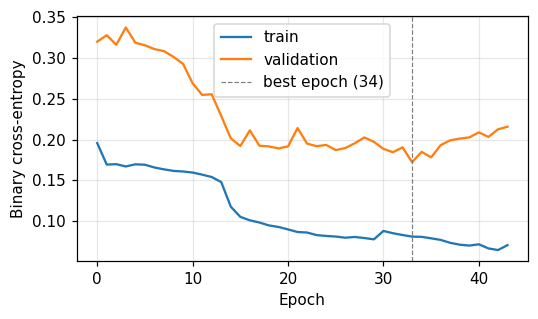

In [ ]:
X_tr, X_va, X_te = W["train"][0], W["val"][0], W["test"][0]
x_min, x_max = X_tr.min(), X_tr.max()
scale = lambda X: (X - x_min) / (x_max - x_min)

tf.keras.utils.set_random_seed(SEED)
clf = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(LOOKBACK, 1)),
    tf.keras.layers.LSTM(HP["units"]),
    tf.keras.layers.Dense(1, activation="sigmoid"),          # output = probability of a ramp in the next 60 s
])
clf.compile(optimizer=tf.keras.optimizers.Adam(HP["learning_rate"]), loss="binary_crossentropy")

stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["patience"], restore_best_weights=True)
hist = clf.fit(scale(X_tr), y_tr, validation_data=(scale(X_va), y_va),
               epochs=HP["max_epochs"], batch_size=HP["batch_size"], callbacks=[stop], verbose=2)

best = int(np.argmin(hist.history["val_loss"])) + 1
plt.figure(figsize=(5, 3))
plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="validation")
plt.axvline(best - 1, color="gray", ls="--", lw=0.8, label=f"best epoch ({best})")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy"); plt.legend(); plt.tight_layout(); plt.show()

prob["LSTM"] = clf.predict(scale(X_te), verbose=0).ravel()

## 9. Results
Scores on both test days together, and on the broken-cloud day alone (the clear day has no ramps, so separation can only be measured where ramps occur or together with it).

In [ ]:
def scores(y, p, p_const):
    bs, bs_ref = brier_score_loss(y, p), brier_score_loss(y, p_const)
    return {"ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p),
            "Brier score": bs,
            "Brier skill score": 1 - bs / bs_ref}

rows = []
for period, m in [("both test days", np.ones(len(y_te), bool)), ("broken-cloud day", broken)]:
    for name, p in prob.items():
        rows.append({"period": period, "method": name, **scores(y_te[m], p[m], prob["constant"][m])})
table = pd.DataFrame(rows).set_index(["period", "method"])
display(table.round(3))
print(f"No-skill reference: ROC-AUC = 0.5; PR-AUC = share of ramp minutes "
      f"({y_te.mean():.3f} both days, {y_te[broken].mean():.3f} broken-cloud day)")

ROC-AUC  PR-AUC  Brier score  \
period           method                                              
both test days   constant               0.500   0.078        0.073   
                 recent-ramps rule      0.914   0.491        0.044   
                 logistic regression    0.966   0.627        0.044   
                 LSTM                   0.911   0.524        0.048   
broken-cloud day constant               0.500   0.156        0.145   
                 recent-ramps rule      0.872   0.499        0.088   
                 logistic regression    0.925   0.628        0.088   
                 LSTM                   0.877   0.538        0.095   

                                      Brier skill score  
period           method                                  
both test days   constant                         0.000  
                 recent-ramps rule                0.400  
                 logistic regression              0.399  
                 LSTM                             0.349  
broken-cloud day constant                         0.000  
                 recent-ramps rule                0.393  
                 logistic regression              0.393  
                 LSTM                             0.343

No-skill reference: ROC-AUC = 0.5; PR-AUC = share of ramp minutes (0.078 both days, 0.156 broken-cloud day)


**Results: forecasting the chance of a ramp in the next 60 s (1 seed)**

*How to read the scores:* ROC-AUC tells how well a method ranks minutes with a coming ramp above minutes without one (0.5 = guessing, 1 = perfect). PR-AUC focuses on the rare ramp minutes (no skill = share of ramp minutes: 0.078 on both test days, 0.156 on the broken-cloud day). The Brier score is the mean squared error of the probabilities (lower is better), and the Brier skill score shows the improvement over the constant method (0 = none).

- **Ramp risk is clearly predictable from past irradiance.** All methods except the constant reach a ROC-AUC of 0.87–0.93 and a Brier skill score of 0.34–0.39 on the broken-cloud day. This confirms the data exploration: the chance of a ramp can be forecast, although its exact timing cannot.
- **The logistic regression is the best method** (broken-cloud day: ROC-AUC 0.925, PR-AUC 0.628, Brier skill score 0.393). It beats the recent-ramps rule (0.872, 0.499, 0.393) because it also uses the variability of the 10-s changes in the last 1 and 5 minutes: even fluctuations below the ramp threshold indicate that clouds are around.
- **The LSTM does not beat the simple methods.** Its ROC-AUC is about the same as the rule (0.877), its PR-AUC lies between the rule and the logistic regression (0.538), and its probabilities are less accurate (Brier skill score 0.343).

**Conclusion.** Forecasting ramp risk works, but in this quick test (one seed, untuned LSTM) three simple variability features with a logistic regression capture the signal better than the LSTM. Next, we check the reliability of the probabilities and test whether the LSTM improves when it also receives these features as inputs.

### Figures
- **Left: ROC curves** on the broken-cloud day. A curve closer to the upper left corner separates better; the diagonal is no skill.
- **Middle: reliability.** The forecasts are grouped by their probability; for each group, the share of cases in which a ramp really followed is plotted. A reliable method lies on the diagonal.
- **Right:** the LSTM's probability over one hour of the broken-cloud day, with the times of real ramps marked.

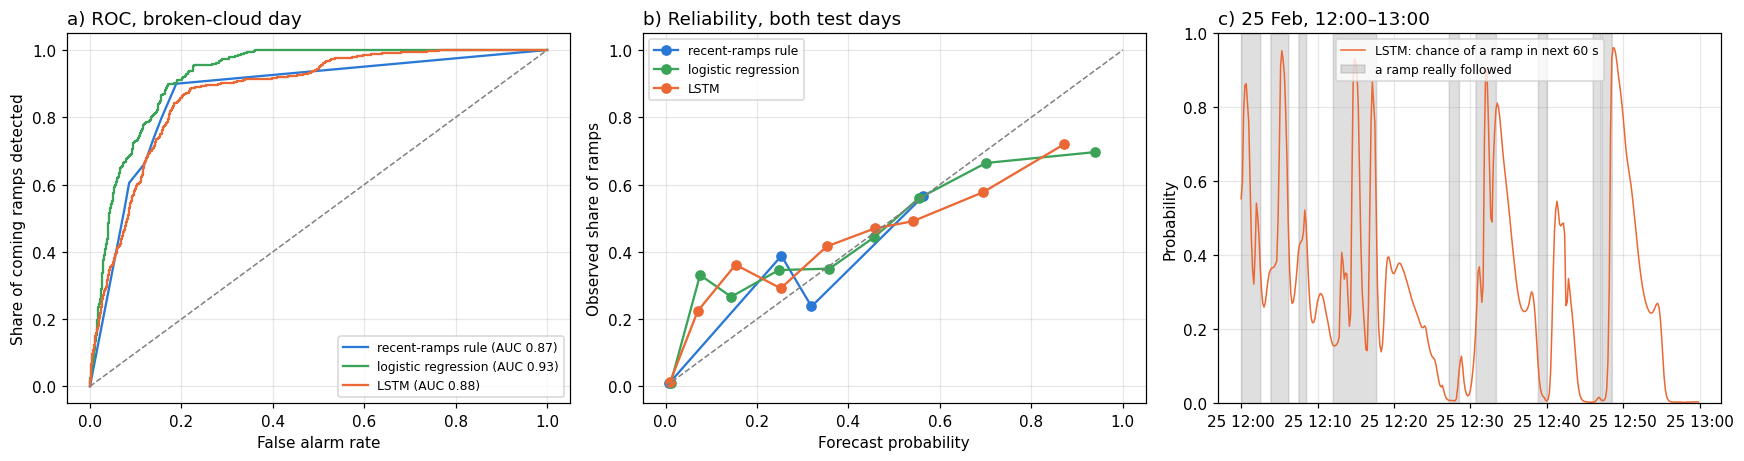

In [ ]:
COLORS = {"constant": "#8a8984", "recent-ramps rule": "#2a78d6", "logistic regression": "#3aa357", "LSTM": "#eb6834"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))

# ---- ROC curves (broken-cloud day) ----
for name, p in prob.items():
    if name == "constant":
        continue
    fpr, tpr, _ = roc_curve(y_te[broken], p[broken])
    ax[0].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(y_te[broken], p[broken]):.2f})")
ax[0].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
ax[0].set_xlabel("False alarm rate"); ax[0].set_ylabel("Share of coming ramps detected")
ax[0].set_title("a) ROC, broken-cloud day", loc="left"); ax[0].legend(fontsize=8)

# ---- Reliability (both test days) ----
bins = np.array([0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0])
for name, p in prob.items():
    if name == "constant":
        continue
    g = pd.DataFrame({"p": p, "y": y_te}).groupby(pd.cut(p, bins, include_lowest=True), observed=True)
    rel = g.agg(mean_p=("p", "mean"), freq=("y", "mean"), n=("y", "size"))
    rel = rel[rel["n"] >= 20]                                   # skip groups with very few cases
    ax[1].plot(rel["mean_p"], rel["freq"], "-o", color=COLORS[name], label=name)
ax[1].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
ax[1].set_xlabel("Forecast probability"); ax[1].set_ylabel("Observed share of ramps")
ax[1].set_title("b) Reliability, both test days", loc="left"); ax[1].legend(fontsize=8)

# ---- LSTM probability over one hour, with real ramps ----
show = (t_te >= "2013-02-25 12:00") & (t_te < "2013-02-25 13:00")
ax[2].plot(t_te[show], prob["LSTM"][show], color=COLORS["LSTM"], lw=1, label="LSTM: chance of a ramp in next 60 s")
ax[2].fill_between(t_te[show], 0, y_te[show], color="gray", alpha=0.25, step="post", label="a ramp really followed")
ax[2].set_ylim(0, 1); ax[2].set_ylabel("Probability")
ax[2].set_title("c) 25 Feb, 12:00–13:00", loc="left"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Results: figures**

- **ROC curves (broken-cloud day).** The logistic regression detects the most coming ramps at every false-alarm rate; e.g. at a false-alarm rate of 10 % it detects about 70 % of them, against about 55–60 % for the LSTM and the recent-ramps rule. The rule's curve consists of a few straight segments, since it can only give seven different probabilities.
- **Reliability (both test days).** Between forecast probabilities of about 0.2 and 0.6, all methods lie close to the diagonal: their probabilities can be taken at face value. At low probabilities (0.05–0.15) ramps occurred somewhat more often than forecast, and at high probabilities (above 0.8) less often (forecasts of about 0.9 were followed by a ramp in about 70 % of the cases). These groups contain fewer cases.
- **Probability over one hour (25 Feb, 12:00–13:00).** The LSTM's probability drops close to 0 in calm periods and rises to 0.8–0.95 during clusters of ramps. However, it rises only after the first ramp of a cluster has occurred (e.g. around 12:26): the model recognises that a restless period continues, but not that it is about to begin. Some false alarms occur (e.g. 12:17–12:20, probability 0.3–0.4 without a following ramp).

**Conclusion of the test.** The chance of a ramp in the next 60 s can be forecast well from past irradiance (ROC-AUC up to 0.93, reasonably reliable probabilities), but mainly as "a restless period is going on", not as a warning before it starts. A logistic regression with three simple variability features does this better than the LSTM.